# 02 · Fund Substitution: which funds can credibly fill the same portfolio role?

**Question.** For a fund an advisor already holds, which other ETFs or mutual funds would have
delivered nearly the same returns, ideally at lower cost, and will that still be true
*next* period?

A good substitute has (i) high return similarity, (ii) low tracking error, (iii) comparable or better
relative performance, and (iv) lower fees. The catch is that similarity measured in-sample is an
optimistic estimate of similarity out-of-sample. This notebook:

1. Builds pairwise similarity measures from a 60-month formation window (2018–2022).
2. **Learns** to predict *out-of-sample* tracking error between any two funds with a neural
   network on pair features, trained on one half of the funds and tested on the other.
3. Evaluates substitute rankings on the realised 2023–2025 tracking error.
4. Draws a 2-D **neural fund map** (autoencoder) of the universe.
5. Detects share classes of the same portfolio and recommends the cheapest one.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy import stats as sps
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from pfquant import make_universe, stats, plotting
plotting.setup()
pd.set_option("display.float_format", "{:.3f}".format)
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(2)

USE_REAL_DATA = False
if USE_REAL_DATA:
    from pfquant.real_data import load_real_universe
    uni = load_real_universe()
else:
    uni = make_universe()
R, F, funds = uni.fund_returns, uni.factor_returns, uni.funds
HAS_TRUTH = uni.true_weights is not None

test_start = R.index[-36]
form = R.loc[:test_start].iloc[-61:-1]          # 60-month formation window
test = R.loc[test_start:]                        # 36-month evaluation window
ok = form.notna().all() & test.notna().all()
ids = R.columns[ok]
Rf, Rt = form[ids].to_numpy(), test[ids].to_numpy()
meta = funds.loc[ids]
n = len(ids)
print(f"{n} funds with complete data. Formation {form.index[0]:%Y-%m}–{form.index[-1]:%Y-%m}, "
      f"test {test.index[0]:%Y-%m}–{test.index[-1]:%Y-%m}")

622 funds with complete data. Formation 2018-01–2022-12, test 2023-01–2025-12


## 1. Pairwise similarity in the formation window

Everything is computed as dense *n × n* matrices, so all ~300k pairs are scored at once:

| feature | definition |
|---|---|
| `corr` | Pearson correlation of monthly returns |
| `te_is` | in-sample tracking error, √(σᵢ² + σⱼ² − 2σᵢⱼ)·√12 |
| `expo_dist` | ½·L1 distance between RBSA style weights (notebook 01) |
| `resid_corr` | correlation of RBSA residuals (shared active bets) |
| `vol_ratio` | \|log σᵢ/σⱼ\| |
| `same_vehicle`, `fee_diff`, `alpha_diff` | ETF/MF match, fee gap, gap in residual alpha |

In [2]:
def te_matrix(X):
    C = np.cov(X.T)
    v = np.diag(C)
    return np.sqrt(np.clip(v[:, None] + v[None, :] - 2 * C, 0, None) * 12)

W = np.empty((n, F.shape[1])); E = np.empty_like(Rf); alpha = np.empty(n)
Ff = F.loc[form.index].to_numpy()
for j in range(n):
    W[j], a, res, _ = stats.rbsa(Rf[:, j], Ff)
    E[:, j], alpha[j] = res, a * 12

feats = {
    "corr": np.corrcoef(Rf.T),
    "te_is": te_matrix(Rf),
    "expo_dist": 0.5 * np.abs(W[:, None, :] - W[None, :, :]).sum(-1),
    "resid_corr": np.nan_to_num(np.corrcoef(E.T)),
    "vol_ratio": np.abs(np.log(Rf.std(0)[:, None] / Rf.std(0)[None, :])),
    "same_vehicle": (meta["vehicle"].to_numpy(str)[:, None] == meta["vehicle"].to_numpy(str)[None, :]).astype(float),
    "fee_diff": meta["expense_ratio"].values[None, :] - meta["expense_ratio"].values[:, None],
    "alpha_diff": alpha[None, :] - alpha[:, None],
}
te_oos = te_matrix(Rt)                          # what we want to predict
same_port = meta["portfolio_id"].values[:, None] == meta["portfolio_id"].values[None, :]

## 2. How stable is similarity?

For every pair, compare the tracking error measured in 2018–22 with what was realised in 2023–25.
Broad similarity persists, but what matters for a recommendation is the ordering *among the closest
candidates*: is the best in-sample match still the best match next period?


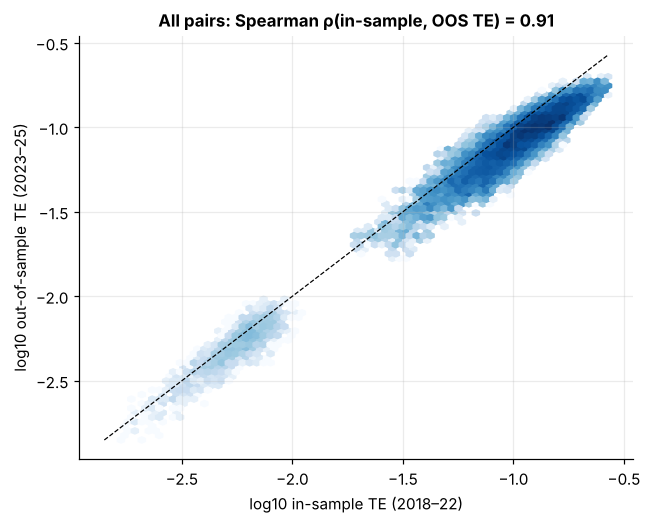

The in-sample best match is also the out-of-sample best for 16% of funds; median OOS rank of the in-sample #1 = 7, it falls outside the OOS top-5 for 53% of funds.


In [3]:
iu = np.triu_indices(n, 1)
mask = ~same_port[iu]
x, yv = feats["te_is"][iu][mask], te_oos[iu][mask]
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(np.log10(x), np.log10(yv), gridsize=70, bins="log", cmap="Blues", mincnt=1)
lim = [np.log10(min(x.min(), yv.min())), np.log10(max(x.max(), yv.max()))]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set_xlabel("log10 in-sample TE (2018–22)"); ax.set_ylabel("log10 out-of-sample TE (2023–25)")
rho_all = sps.spearmanr(x, yv).statistic
a_is = np.where(same_port | np.eye(n, dtype=bool), np.inf, feats["te_is"])
a_oos = np.where(same_port | np.eye(n, dtype=bool), np.inf, te_oos)
best_is, best_oos = a_is.argmin(1), a_oos.argmin(1)
rank_of_is_best = (a_oos < a_oos[np.arange(n), best_is][:, None]).sum(1) + 1
ax.set_title(f"All pairs: Spearman ρ(in-sample, OOS TE) = {rho_all:.2f}")
plotting.save(fig, "02_te_is_vs_oos")
print(f"The in-sample best match is also the out-of-sample best for {np.mean(best_is == best_oos):.0%} of funds; "
      f"median OOS rank of the in-sample #1 = {np.median(rank_of_is_best):.0f}, "
      f"it falls outside the OOS top-5 for {np.mean(rank_of_is_best > 5):.0%} of funds.")

## 3. Learning to predict out-of-sample tracking error

Split the *funds* in half. Pairs whose query fund is in the training half train the models;
pairs whose query fund is in the test half are scored. Target: log OOS tracking error. Share-class
siblings (same underlying portfolio) are excluded here and handled in §6.

Models: single-feature heuristics (in-sample TE, correlation, exposure distance), gradient boosting,
and a PyTorch MLP.

In [4]:
fnames = list(feats)
rng = np.random.default_rng(0)
is_train_q = np.zeros(n, bool); is_train_q[rng.permutation(n)[: n // 2]] = True

qi, ci = np.where(~np.eye(n, dtype=bool) & ~same_port)
Xp = np.column_stack([feats[k][qi, ci] for k in fnames])
Xp[:, fnames.index("te_is")] = np.log(Xp[:, fnames.index("te_is")])
yp = np.log(te_oos[qi, ci])
tr, te_ = is_train_q[qi], ~is_train_q[qi]
mu, sd = Xp[tr].mean(0), Xp[tr].std(0)
Xs = (Xp - mu) / sd
print(f"{tr.sum():,} training pairs, {te_.sum():,} test pairs, {len(fnames)} features")

gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, random_state=0)
gbm.fit(Xp[tr], yp[tr])

class PairMLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 64), nn.SiLU(), nn.Dropout(0.1),
                                 nn.Linear(64, 64), nn.SiLU(), nn.Dropout(0.1), nn.Linear(64, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

mlp = PairMLP(Xs.shape[1])
opt = torch.optim.AdamW(mlp.parameters(), lr=2e-3, weight_decay=1e-4)
Xt, Yt = torch.tensor(Xs[tr], dtype=torch.float32), torch.tensor(yp[tr], dtype=torch.float32)
val = torch.rand(len(Xt)) < 0.1
hist = []
for epoch in range(25):
    mlp.train()
    perm = torch.randperm(int((~val).sum()))
    Xa, Ya = Xt[~val][perm], Yt[~val][perm]
    for b in range(0, len(Xa), 1024):
        opt.zero_grad()
        loss = nn.functional.mse_loss(mlp(Xa[b:b + 1024]), Ya[b:b + 1024])
        loss.backward(); opt.step()
    mlp.eval()
    with torch.no_grad():
        hist.append(nn.functional.mse_loss(mlp(Xt[val]), Yt[val]).item())
with torch.no_grad():
    pred_mlp = mlp(torch.tensor(Xs, dtype=torch.float32)).numpy()
pred = {
    "In-sample TE": Xp[:, fnames.index("te_is")],
    "Correlation": -Xp[:, fnames.index("corr")],
    "Exposure distance": Xp[:, fnames.index("expo_dist")],
    "Gradient boosting": gbm.predict(Xp),
    "Neural net (MLP)": pred_mlp,
}
print(f"MLP validation MSE by epoch: {hist[0]:.3f} → {hist[-1]:.3f}")

192,971 training pairs, 192,957 test pairs, 8 features


MLP validation MSE by epoch: 0.030 → 0.019


### Ranking evaluation (test-half query funds only)

For each query fund, rank all candidates by the model score and compare with the realised
2023–25 tracking error:
* **Spearman ρ** between predicted and realised TE across candidates,
* **Precision@10**: share of the predicted top-10 that are in the realised top-10,
* **OOS TE of top pick**: what the advisor would actually have experienced substituting with #1,
* **Regret**: top-pick OOS TE minus the best achievable (oracle) OOS TE.

In [5]:
def evaluate(score):
    out = []
    for q in np.flatnonzero(~is_train_q):
        m = qi == q
        s, y = score[m], yp[m]
        top_pred = np.argsort(s)[:10]; top_true = np.argsort(y)[:10]
        out.append(dict(spearman=sps.spearmanr(s, y).statistic,
                        p_at_10=len(set(top_pred) & set(top_true)) / 10,
                        top1_te=np.exp(y[top_pred[0]]), regret=np.exp(y[top_pred[0]]) - np.exp(y.min())))
    return pd.DataFrame(out).median()

ev = pd.DataFrame({k: evaluate(v) for k, v in pred.items()}).T
ev.columns = ["Spearman ρ", "Precision@10", "OOS TE of top pick", "Regret vs oracle"]
display(ev.style.format({"Spearman ρ": "{:.3f}", "Precision@10": "{:.2f}",
                         "OOS TE of top pick": "{:.2%}", "Regret vs oracle": "{:.2%}"})
          .highlight_max(subset=["Spearman ρ", "Precision@10"], color="#d6eadf")
          .highlight_min(subset=["OOS TE of top pick", "Regret vs oracle"], color="#d6eadf"))

,Spearman ρ,Precision@10,OOS TE of top pick,Regret vs oracle
In-sample TE,0.882,0.70,3.54%,0.10%
Correlation,0.767,0.60,3.51%,0.13%
Exposure distance,0.586,0.30,4.43%,0.61%
Gradient boosting,0.911,0.60,3.44%,0.13%
Neural net (MLP),0.888,0.70,3.41%,0.09%


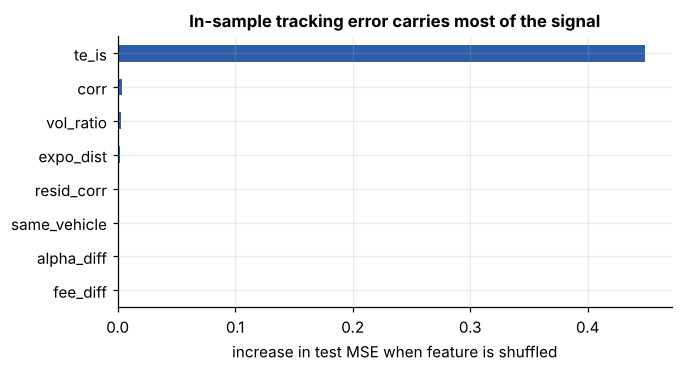

In [6]:
sub = np.flatnonzero(te_)[:: max(1, te_.sum() // 30000)]
def mlp_predict(X):
    with torch.no_grad():
        return mlp(torch.tensor((X - mu) / sd, dtype=torch.float32)).numpy()
base_mse = np.mean((mlp_predict(Xp[sub]) - yp[sub]) ** 2)
rng_pi = np.random.default_rng(0)
importance = []
for k in range(len(fnames)):                       # permutation importance, 3 repeats
    deltas = []
    for _ in range(3):
        Xperm = Xp[sub].copy(); Xperm[:, k] = rng_pi.permutation(Xperm[:, k])
        deltas.append(np.mean((mlp_predict(Xperm) - yp[sub]) ** 2) - base_mse)
    importance.append(np.mean(deltas))
imp = pd.Series(importance, index=fnames).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
imp.plot.barh(ax=ax, color=plotting.PALETTE[0])
ax.set_xlabel("increase in test MSE when feature is shuffled")
ax.set_title("In-sample tracking error carries most of the signal")
plotting.save(fig, "02_feature_importance")

## 4. A substitution card

An advisor holds an expensive active fund. Which cheaper funds can take its seat? Candidates are
ranked by the neural net's predicted OOS tracking error among funds with a lower expense ratio.
The realised 2023–25 numbers are shown alongside for honesty (they are unknown at decision time).

In [7]:
pred_mat = np.full((n, n), np.nan); pred_mat[qi, ci] = np.exp(pred_mlp)
fee = meta["expense_ratio"].to_numpy()
cheaper_ok = (fee[None, :] < fee[:, None]) & ~same_port & ~np.eye(n, dtype=bool)
best_cheaper_te = np.where(cheaper_ok, pred_mat, np.inf).min(1)
pool = meta[(~meta["passive"]) & (~is_train_q) & (meta["share_class"] != "C") & (best_cheaper_te < 0.03)]
target = pool["expense_ratio"].idxmax() if len(pool) else ids[0]
t = ids.get_loc(target)
cand = pd.DataFrame({
    "category": meta["category"], "vehicle": meta["vehicle"], "expense_ratio": meta["expense_ratio"],
    "fee_saving": meta.loc[target, "expense_ratio"] - meta["expense_ratio"],
    "corr_2018_22": feats["corr"][t], "TE_2018_22": feats["te_is"][t],
    "predicted_TE_OOS": pred_mat[t], "realised_TE_2023_25": te_oos[t],
    "alpha_2018_22": alpha,
    "realised_excess_vs_target_2023_25": (Rt.mean(0) - Rt[:, t].mean()) * 12,
}, index=ids)
cand = cand[(cand.index != target) & (~same_port[t]) & (cand["fee_saving"] > 0)]
card = cand.nsmallest(5, "predicted_TE_OOS")
print(f"Target: {target} · {meta.loc[target, 'category']} · {meta.loc[target, 'vehicle']} · "
      f"expense ratio {meta.loc[target, 'expense_ratio']:.2%}")
display(card.style.format({c: "{:.2%}" for c in card.columns if c not in ("category", "vehicle", "corr_2018_22")}
                          | {"corr_2018_22": "{:.3f}"}))

Target: F0121A · Foreign Large Blend · MF · expense ratio 1.34%


,category,vehicle,expense_ratio,fee_saving,corr_2018_22,TE_2018_22,predicted_TE_OOS,realised_TE_2023_25,alpha_2018_22,realised_excess_vs_target_2023_25
F0133,Foreign Large Blend,MF,0.28%,1.06%,0.984,2.58%,2.19%,2.64%,-0.34%,1.45%
F0208,Foreign Large Blend,ETF,0.17%,1.17%,0.984,2.59%,2.21%,2.67%,-0.16%,1.54%
F0136,Foreign Large Blend,MF,0.30%,1.04%,0.984,2.57%,2.22%,2.67%,-0.33%,1.38%
F0150,Foreign Large Blend,MF,0.25%,1.08%,0.983,2.68%,2.23%,2.78%,-0.47%,1.50%
F0496,Foreign Large Blend,ETF,0.18%,1.16%,0.984,2.61%,2.23%,2.74%,-0.25%,1.59%


## 5. Neural fund map

An autoencoder compresses each fund's standardised 60-month return path into 2 numbers and
reconstructs it. Funds that behave alike land close together. Colour is the (unseen) category label;
k-NN purity measures how well the map groups funds of the same category.

,10-NN category purity
Autoencoder (2-D),0.886
PCA (2-D),0.733
In-sample TE (full),0.951


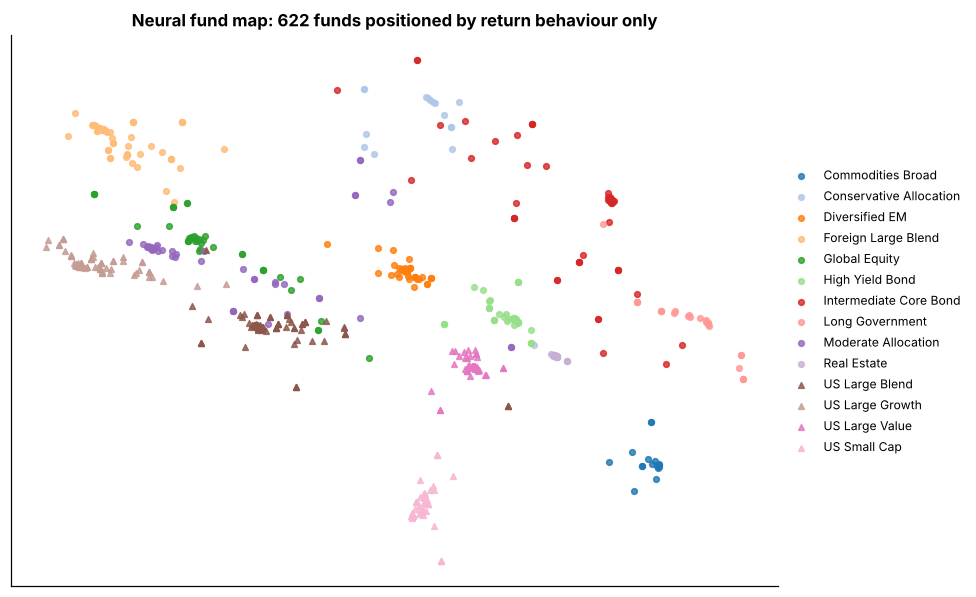

In [8]:
Z = (Rf - Rf.mean(0)) / Rf.std(0)
Zt = torch.tensor(Z.T, dtype=torch.float32)
class AE(nn.Module):
    def __init__(self, d, k=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 64), nn.SiLU(), nn.Linear(64, 16), nn.SiLU(), nn.Linear(16, k))
        self.dec = nn.Sequential(nn.Linear(k, 16), nn.SiLU(), nn.Linear(16, 64), nn.SiLU(), nn.Linear(64, d))
    def forward(self, x):
        z = self.enc(x); return z, self.dec(z)
torch.manual_seed(1)
ae = AE(Z.shape[0])
opt = torch.optim.Adam(ae.parameters(), lr=3e-3)
for epoch in range(1500):
    opt.zero_grad()
    z, rec = ae(Zt)
    loss = nn.functional.mse_loss(rec, Zt); loss.backward(); opt.step()
with torch.no_grad():
    emb = ae(Zt)[0].numpy()
pca2 = PCA(2).fit_transform(Z.T)

def knn_purity(X, labels, k=10):
    d = ((X[:, None] - X[None]) ** 2).sum(-1); np.fill_diagonal(d, np.inf)
    nn_idx = np.argsort(d, 1)[:, :k]
    return (labels[nn_idx] == labels[:, None]).mean()
lab = meta["category"].to_numpy(str)
purity = pd.Series({"Autoencoder (2-D)": knn_purity(emb, lab), "PCA (2-D)": knn_purity(pca2, lab),
                    "In-sample TE (full)": (lambda d: (lab[np.argsort(np.where(np.eye(n, dtype=bool), np.inf, d), 1)[:, :10]]
                                                       == lab[:, None]).mean())(feats["te_is"])})
display(purity.to_frame("10-NN category purity"))

fig, ax = plt.subplots(figsize=(9, 6.5))
cmap = plt.get_cmap("tab20")
for i, c in enumerate(sorted(set(lab))):
    m = lab == c
    ax.scatter(emb[m, 0], emb[m, 1], s=14, color=cmap(i), label=c, alpha=0.8,
               marker="o" if i < 10 else "^")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
ax.set_title(f"Neural fund map: {n} funds positioned by return behaviour only")
ax.set_xticks([]); ax.set_yticks([])
plotting.save(fig, "02_fund_map")

## 6. Same portfolio, different share class

Multiple share classes of one mutual fund have identical holdings and differ only by fee. Their
return difference is a constant, so the tracking error between them is ~0 and correlation is ~1.
A substitution engine should collapse them and surface the cheapest class an advisor can access.

In [9]:
dup = (feats["te_is"] < 0.0005) & ~np.eye(n, dtype=bool)
pairs_found = set(zip(*np.where(np.triu(dup, 1))))
pairs_true = set(zip(*np.where(np.triu(same_port, 1))))
prec = len(pairs_found & pairs_true) / max(len(pairs_found), 1)
rec = len(pairs_found & pairs_true) / max(len(pairs_true), 1)
print(f"Share-class pairs detected: {len(pairs_found)}  ·  precision {prec:.1%}  ·  recall {rec:.1%}")

groups = meta.groupby("portfolio_id").filter(lambda g: len(g) > 1)
cheapest = groups.loc[groups.groupby("portfolio_id")["expense_ratio"].idxmin()]
saving = (groups.groupby("portfolio_id")["expense_ratio"].max() - groups.groupby("portfolio_id")["expense_ratio"].min())
print(f"{groups['portfolio_id'].nunique()} multi-class portfolios; moving to the cheapest class saves "
      f"{saving.min():.2%}–{saving.max():.2%} a year in fees with identical exposure.")

Share-class pairs detected: 167  ·  precision 100.0%  ·  recall 100.0%
79 multi-class portfolios; moving to the cheapest class saves 0.25%–1.00% a year in fees with identical exposure.


## Takeaways

* **Broad similarity is stable; fine ordering is not.** In-sample and out-of-sample tracking error are
  highly rank-correlated across all pairs, yet the in-sample best match is the realised best match for
  only a minority of funds. That ordering among close candidates is where a model can add value.
* **Learning helps, modestly and honestly.** In-sample TE is already a strong baseline. Gradient boosting
  gives the best full ranking (highest Spearman ρ) and the neural net the lowest realised tracking
  error and regret for the top recommendation; correlation or exposure distance alone are clearly
  worse. Gains are small but come for free once the pair features exist.
* **The output is a decision, not a score.** The substitution card pairs predicted OOS tracking error
  with fee savings, the trade-off an advisor actually makes.
* **Hygiene matters.** Share classes are recovered from returns alone (100 % precision and recall here); collapsing
  them avoids recommending a fund's own sibling as a "substitute".

**Limitations.** One formation/test split; a production version would roll this through time, add
holdings-based overlap (N-PORT) and treat liquidity and platform availability as constraints.